# Day 038 | Polynomial, Ridge & Lasso Regression
## 100 Days of ML for Geotechnical Engineering
**Phase:** Classical Machine Learning

**Author:** Ripon Chandra Malo  
**Date:** 2026

---

## What We Will Learn Today

| Concept | What It Means | Geotechnical Example |
|---------|--------------|---------------------|
| **Polynomial Regression** | Fit curves instead of straight lines | Settlement vs pressure is nonlinear |
| **Overfitting** | Model memorizes noise instead of learning patterns | High-degree polynomial wiggles through every point |
| **Ridge (L2)** | Penalize large coefficients (shrink toward zero) | Keep all features but reduce their influence |
| **Lasso (L1)** | Penalize coefficients (some become exactly zero) | Automatic feature selection for soil parameters |
| **Alpha** | Regularization strength (higher = more penalty) | Tuning how much to penalize complexity |
| **Bias-Variance Tradeoff** | Simple models underfit, complex models overfit | Finding the sweet spot for settlement prediction |

---

## Our Geotechnical Problem

We have **plate load test data** from a foundation investigation. For various applied pressures,
footing widths, and depths, we measured the resulting settlement.

**Goal:** Predict settlement from applied pressure, footing width, and embedment depth.
The relationship is nonlinear — a straight line will not work. But a high-degree polynomial
will overfit. Regularization is the answer.

---

## Part 1: Generate and Explore Load Test Data

We create synthetic plate load test data with realistic geotechnical relationships.

---

In [1]:
# ─────────────────────────────────────────────────────
# GENERATE SYNTHETIC LOAD TEST DATA
# ─────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
n = 60

# ── Generate realistic features ──
applied_pressure = np.random.uniform(50, 500, n)       # kPa
footing_width = np.random.choice([0.3, 0.45, 0.6, 0.75, 1.0], n)  # meters
depth = np.random.uniform(0.5, 3.0, n)                 # meters

# ── Settlement model (nonlinear, realistic) ──
# settlement ~ pressure * width / (depth * modulus) + noise
# Higher pressure -> more settlement
# Wider footing -> more settlement (larger stressed zone)
# Deeper embedment -> less settlement (confinement effect)
settlement = (
    0.8 * applied_pressure * footing_width / (depth * 50)
    + 0.002 * applied_pressure**1.3 / (depth**0.5)
    + np.random.normal(0, 1.5, n)
)
settlement = np.clip(settlement, 0.5, None)  # no negative settlement

df = pd.DataFrame({
    'applied_pressure': applied_pressure.round(1),
    'footing_width': footing_width,
    'depth': depth.round(2),
    'settlement': settlement.round(2)
})

# ── Save for reproducibility ──
df.to_csv('load_test_data.csv', index=False)

print("Plate Load Test Dataset")
print("=" * 55)
print(f"Shape: {df.shape}")
print(f"\nDescriptive Statistics:")
print(df.describe().round(2))
print(f"\nFirst 5 rows:")
df.head()

Plate Load Test Dataset
Shape: (60, 4)

Descriptive Statistics:
       applied_pressure  footing_width  depth  settlement
count             60.00          60.00  60.00       60.00
mean             260.38           0.62   1.71        4.69
std              137.44           0.26   0.74        3.27
min               59.30           0.30   0.52        0.50
25%              133.02           0.41   1.10        2.23
50%              251.65           0.60   1.64        4.14
75%              371.30           0.75   2.43        6.70
max              486.50           1.00   2.96       13.65

First 5 rows:


,applied_pressure,footing_width,depth,settlement
0,218.5,1.00,1.07,5.54
1,477.8,0.45,0.69,11.52
2,379.4,1.00,1.22,6.70
3,319.4,0.45,0.90,6.44
4,120.2,0.30,2.82,0.50


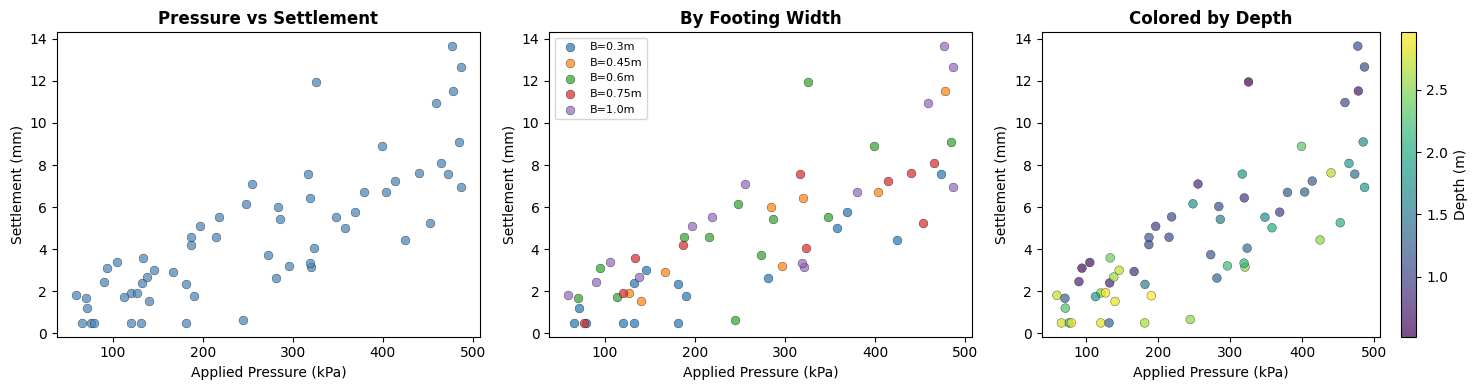

The pressure-settlement relationship is clearly nonlinear.
A straight line will underfit. We need polynomial features.


In [2]:
# ─────────────────────────────────────────────────────
# VISUALIZE THE DATA
# ─────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

ax = axes[0]
ax.scatter(df['applied_pressure'], df['settlement'], c='steelblue',
           edgecolors='black', linewidth=0.3, alpha=0.7, s=40)
ax.set_xlabel('Applied Pressure (kPa)')
ax.set_ylabel('Settlement (mm)')
ax.set_title('Pressure vs Settlement', fontweight='bold')

ax = axes[1]
for w in sorted(df['footing_width'].unique()):
    mask = df['footing_width'] == w
    ax.scatter(df.loc[mask, 'applied_pressure'], df.loc[mask, 'settlement'],
               label=f'B={w}m', alpha=0.7, s=40, edgecolors='black', linewidth=0.3)
ax.set_xlabel('Applied Pressure (kPa)')
ax.set_ylabel('Settlement (mm)')
ax.set_title('By Footing Width', fontweight='bold')
ax.legend(fontsize=8)

ax = axes[2]
scatter = ax.scatter(df['applied_pressure'], df['settlement'],
                     c=df['depth'], cmap='viridis', edgecolors='black',
                     linewidth=0.3, alpha=0.7, s=40)
plt.colorbar(scatter, ax=ax, label='Depth (m)')
ax.set_xlabel('Applied Pressure (kPa)')
ax.set_ylabel('Settlement (mm)')
ax.set_title('Colored by Depth', fontweight='bold')

plt.tight_layout()
plt.savefig('load_test_scatter.png', dpi=100, bbox_inches='tight')
plt.show()

print("The pressure-settlement relationship is clearly nonlinear.")
print("A straight line will underfit. We need polynomial features.")

## Part 2: Polynomial Regression — Fitting Curves

Polynomial regression transforms features into higher-degree terms:
- **Degree 1:** `x` (linear)
- **Degree 2:** `x, x^2` (quadratic)
- **Degree 3:** `x, x^2, x^3` (cubic)

With multiple features (pressure, width, depth), we also get **interaction terms**
like `pressure * width` and `pressure * depth`.

---

In [3]:
# ─────────────────────────────────────────────────────
# POLYNOMIAL FEATURES — How they work
# ─────────────────────────────────────────────────────
# Start with just pressure for a clear demonstration
X_demo = df[['applied_pressure']].values[:5]

print("How PolynomialFeatures Works (degree=3)")
print("=" * 55)
print(f"Original feature: applied_pressure")
print(f"Input shape: {X_demo.shape}\n")

for deg in [1, 2, 3]:
    poly = PolynomialFeatures(degree=deg, include_bias=False)
    X_poly = poly.fit_transform(X_demo)
    print(f"Degree {deg}: {X_poly.shape[1]} features -> {poly.get_feature_names_out()}")

print("\nWith 3 original features at degree 3:")
poly_3 = PolynomialFeatures(degree=3, include_bias=False)
X_all = df[['applied_pressure', 'footing_width', 'depth']].values
X_poly_3 = poly_3.fit_transform(X_all)
print(f"  Input:  3 features")
print(f"  Output: {X_poly_3.shape[1]} features (including interactions and powers)")
print(f"  Feature names: {poly_3.get_feature_names_out()[:10]}... ")
print(f"\nWarning: Features grow fast! Degree 5 with 3 inputs = {PolynomialFeatures(degree=5, include_bias=False).fit_transform(X_all).shape[1]} features")

How PolynomialFeatures Works (degree=3)
Original feature: applied_pressure
Input shape: (5, 1)

Degree 1: 1 features -> ['x0']
Degree 2: 2 features -> ['x0' 'x0^2']
Degree 3: 3 features -> ['x0' 'x0^2' 'x0^3']

With 3 original features at degree 3:
  Input:  3 features
  Output: 19 features (including interactions and powers)
  Feature names: ['x0' 'x1' 'x2' 'x0^2' 'x0 x1' 'x0 x2' 'x1^2' 'x1 x2' 'x2^2' 'x0^3']... 



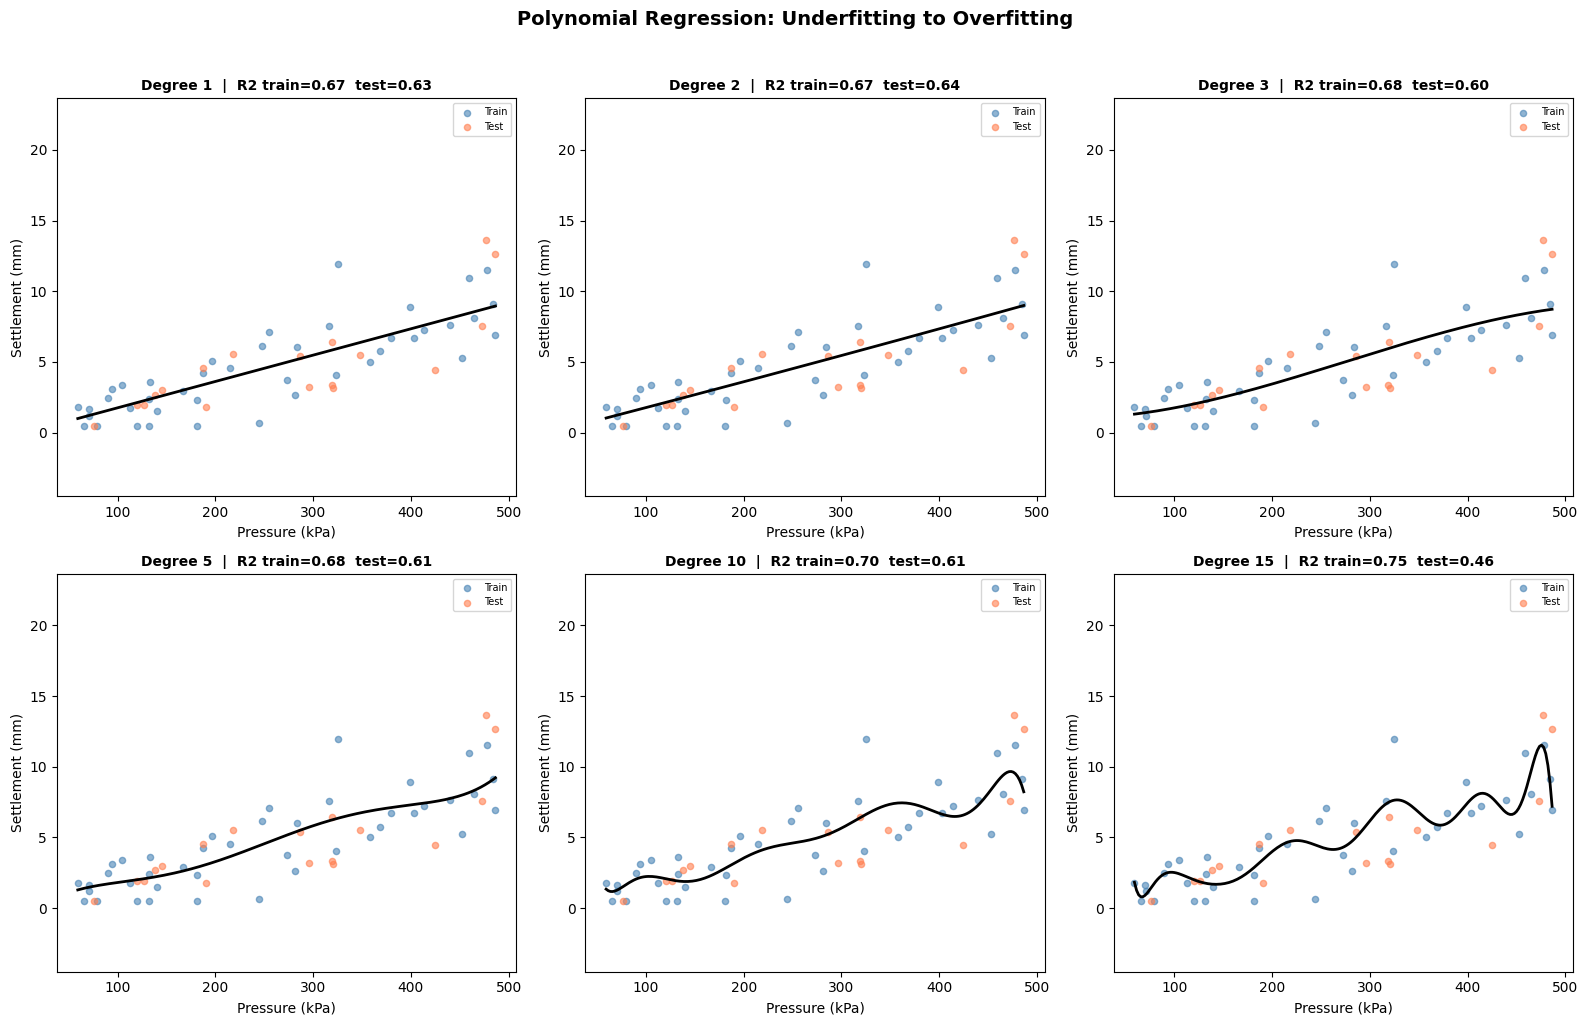

 Degree  R2_train  R2_test  RMSE_test
      1  0.673703 0.634475   2.071209
      2  0.673751 0.638016   2.061153
      3  0.676083 0.603934   2.156001
      5  0.680169 0.614067   2.128244
     10  0.698022 0.607859   2.145294
     15  0.750448 0.462861   2.510781

As degree increases:
  - Train R2 always improves (more flexibility to fit training data)
  - Test R2 improves at first, then collapses (overfitting)
  - The curve starts wiggling wildly between data points


In [4]:
# ─────────────────────────────────────────────────────
# DEMONSTRATE OVERFITTING WITH HIGH DEGREE
# ─────────────────────────────────────────────────────
# Use just pressure -> settlement for visualization
X_1d = df[['applied_pressure']].values
y = df['settlement'].values

X_train, X_test, y_train, y_test = train_test_split(
    X_1d, y, test_size=0.3, random_state=42
)

# ── Fit polynomials of increasing degree ──
degrees = [1, 2, 3, 5, 10, 15]
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
x_plot = np.linspace(X_1d.min(), X_1d.max(), 200).reshape(-1, 1)

results = []
for ax, deg in zip(axes.ravel(), degrees):
    pipe = Pipeline([
        ('poly', PolynomialFeatures(degree=deg, include_bias=False)),
        ('scaler', StandardScaler()),
        ('lr', LinearRegression())
    ])
    pipe.fit(X_train, y_train)

    y_pred_train = pipe.predict(X_train)
    y_pred_test = pipe.predict(X_test)

    r2_train = r2_score(y_train, y_pred_train)
    r2_test = r2_score(y_test, y_pred_test)
    rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))

    results.append({'Degree': deg, 'R2_train': r2_train,
                    'R2_test': r2_test, 'RMSE_test': rmse_test})

    # ── Plot ──
    ax.scatter(X_train, y_train, c='steelblue', s=20, alpha=0.6, label='Train')
    ax.scatter(X_test, y_test, c='coral', s=20, alpha=0.6, label='Test')
    y_plot = pipe.predict(x_plot)
    ax.plot(x_plot, y_plot, 'k-', linewidth=2)
    ax.set_title(f'Degree {deg}  |  R2 train={r2_train:.2f}  test={r2_test:.2f}',
                 fontweight='bold', fontsize=10)
    ax.set_xlabel('Pressure (kPa)')
    ax.set_ylabel('Settlement (mm)')
    ax.set_ylim(y.min() - 5, y.max() + 10)
    ax.legend(fontsize=7)

plt.suptitle('Polynomial Regression: Underfitting to Overfitting',
             fontweight='bold', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('polynomial_degrees.png', dpi=100, bbox_inches='tight')
plt.show()

print(pd.DataFrame(results).to_string(index=False))
print("\nAs degree increases:")
print("  - Train R2 always improves (more flexibility to fit training data)")
print("  - Test R2 improves at first, then collapses (overfitting)")
print("  - The curve starts wiggling wildly between data points")

## Part 3: Ridge Regression (L2 Regularization)

Ridge regression adds a penalty to the loss function:

**Loss = MSE + alpha * sum(coefficients^2)**

This shrinks all coefficients toward zero but never makes them exactly zero.
The effect: smoother predictions, less overfitting.

- **alpha = 0:** No regularization (same as ordinary regression)
- **alpha = large:** Heavy regularization (coefficients near zero, model too simple)

---

In [5]:
# ─────────────────────────────────────────────────────
# RIDGE REGRESSION — Taming overfitting
# ─────────────────────────────────────────────────────
# Use all 3 features with degree-3 polynomial
X_full = df[['applied_pressure', 'footing_width', 'depth']].values
y = df['settlement'].values

X_train, X_test, y_train, y_test = train_test_split(
    X_full, y, test_size=0.3, random_state=42
)

# ── Compare Ridge with different alpha values ──
alphas = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
ridge_results = []

for alpha in alphas:
    pipe = Pipeline([
        ('poly', PolynomialFeatures(degree=3, include_bias=False)),
        ('scaler', StandardScaler()),
        ('ridge', Ridge(alpha=alpha))
    ])
    pipe.fit(X_train, y_train)

    y_pred_train = pipe.predict(X_train)
    y_pred_test = pipe.predict(X_test)

    coefs = pipe.named_steps['ridge'].coef_
    ridge_results.append({
        'Alpha': alpha,
        'R2_train': r2_score(y_train, y_pred_train),
        'R2_test': r2_score(y_test, y_pred_test),
        'RMSE_test': np.sqrt(mean_squared_error(y_test, y_pred_test)),
        'Max_coef': np.max(np.abs(coefs)),
        'Nonzero': np.sum(np.abs(coefs) > 0.01)
    })

ridge_df = pd.DataFrame(ridge_results)
print("Ridge Regression — Effect of Alpha")
print("=" * 70)
print(ridge_df.to_string(index=False))
print("\nAs alpha increases:")
print("  - Coefficients shrink (Max_coef decreases)")
print("  - Train R2 decreases (less flexible)")
print("  - Test R2 can improve if we were overfitting")

Ridge Regression — Effect of Alpha
  Alpha  R2_train  R2_test  RMSE_test  Max_coef  Nonzero
  0.001  0.900408 0.670017   1.967937 25.218628       19
  0.010  0.890772 0.777719   1.615165 10.139956       19
  0.100  0.868730 0.860150   1.281142  3.828704       19
  1.000  0.835615 0.877001   1.201480  1.675785       19
 10.000  0.767549 0.849971   1.326945  0.848940       18
100.000  0.658591 0.736335   1.759105  0.331636       17

As alpha increases:
  - Coefficients shrink (Max_coef decreases)
  - Train R2 decreases (less flexible)
  - Test R2 can improve if we were overfitting


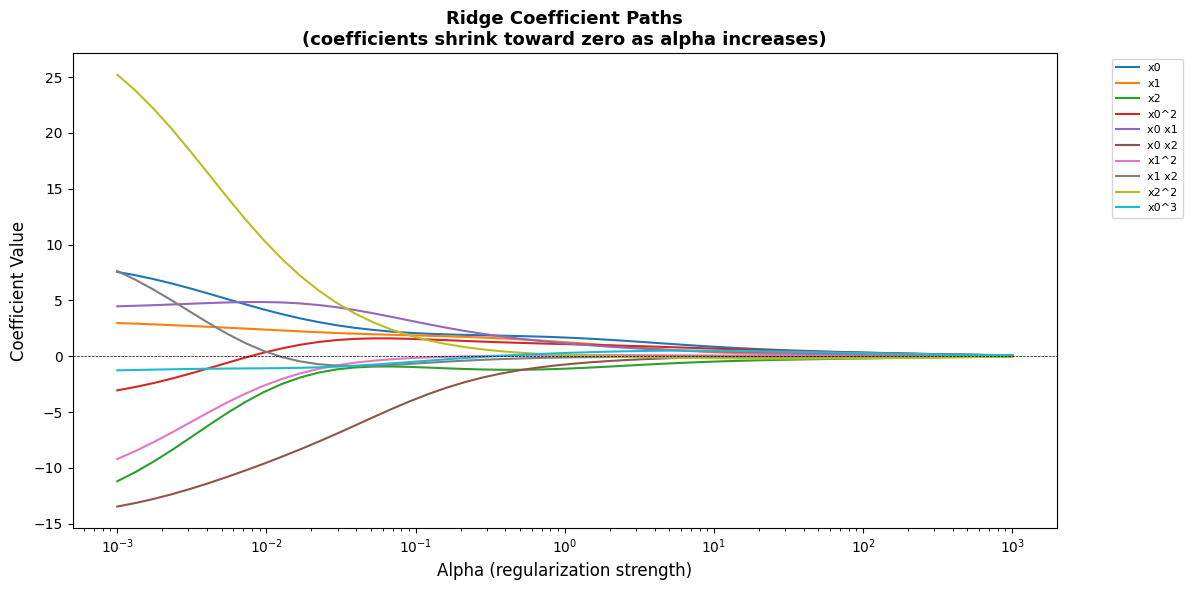

Ridge: all coefficients shrink but never reach exactly zero.
All features remain in the model — just with reduced influence.


In [6]:
# ─────────────────────────────────────────────────────
# VISUALIZE RIDGE COEFFICIENT PATHS
# ─────────────────────────────────────────────────────
# Track how coefficients change with alpha
alpha_range = np.logspace(-3, 3, 50)
coef_paths = []

# Prepare polynomial features once
poly = PolynomialFeatures(degree=3, include_bias=False)
scaler = StandardScaler()
X_train_poly = scaler.fit_transform(poly.fit_transform(X_train))
feature_names = poly.get_feature_names_out()

for alpha in alpha_range:
    ridge = Ridge(alpha=alpha)
    ridge.fit(X_train_poly, y_train)
    coef_paths.append(ridge.coef_)

coef_paths = np.array(coef_paths)

fig, ax = plt.subplots(figsize=(12, 6))
for i in range(min(10, coef_paths.shape[1])):  # plot first 10 coefficients
    ax.plot(alpha_range, coef_paths[:, i], linewidth=1.5,
            label=feature_names[i] if i < 10 else '')

ax.set_xscale('log')
ax.set_xlabel('Alpha (regularization strength)', fontsize=12)
ax.set_ylabel('Coefficient Value', fontsize=12)
ax.set_title('Ridge Coefficient Paths\n(coefficients shrink toward zero as alpha increases)',
             fontweight='bold', fontsize=13)
ax.axhline(0, color='black', linewidth=0.5, linestyle='--')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.savefig('ridge_coef_paths.png', dpi=100, bbox_inches='tight')
plt.show()

print("Ridge: all coefficients shrink but never reach exactly zero.")
print("All features remain in the model — just with reduced influence.")

## Part 4: Lasso Regression (L1 Regularization)

Lasso adds a different penalty:

**Loss = MSE + alpha * sum(|coefficients|)**

The key difference: Lasso can drive coefficients to **exactly zero**, effectively
performing feature selection. This is powerful when you have many polynomial features
but only a few truly matter.

---

In [7]:
# ─────────────────────────────────────────────────────
# LASSO REGRESSION — Feature selection built in
# ─────────────────────────────────────────────────────
lasso_results = []

for alpha in alphas:
    pipe = Pipeline([
        ('poly', PolynomialFeatures(degree=3, include_bias=False)),
        ('scaler', StandardScaler()),
        ('lasso', Lasso(alpha=alpha, max_iter=10000))
    ])
    pipe.fit(X_train, y_train)

    y_pred_train = pipe.predict(X_train)
    y_pred_test = pipe.predict(X_test)

    coefs = pipe.named_steps['lasso'].coef_
    lasso_results.append({
        'Alpha': alpha,
        'R2_train': r2_score(y_train, y_pred_train),
        'R2_test': r2_score(y_test, y_pred_test),
        'RMSE_test': np.sqrt(mean_squared_error(y_test, y_pred_test)),
        'Max_coef': np.max(np.abs(coefs)),
        'Nonzero': np.sum(np.abs(coefs) > 1e-6)
    })

lasso_df = pd.DataFrame(lasso_results)
print("Lasso Regression — Effect of Alpha")
print("=" * 70)
print(lasso_df.to_string(index=False))
print("\nCompare with Ridge:")
print("  - Lasso drives many coefficients to EXACTLY zero (see Nonzero column)")
print("  - Higher alpha = fewer features retained")
print("  - Lasso performs automatic feature selection!")

Lasso Regression — Effect of Alpha
  Alpha  R2_train   R2_test  RMSE_test  Max_coef  Nonzero
  0.001  0.895100  0.743615   1.734648 16.836841       15
  0.010  0.857655  0.873070   1.220525  3.489731       11
  0.100  0.778451  0.800517   1.530094  1.872890        5
  1.000  0.577804  0.524515   2.362293  1.471863        2
 10.000  0.000000 -0.004365   3.433296  0.000000        0
100.000  0.000000 -0.004365   3.433296  0.000000        0

Compare with Ridge:
  - Lasso drives many coefficients to EXACTLY zero (see Nonzero column)
  - Higher alpha = fewer features retained
  - Lasso performs automatic feature selection!


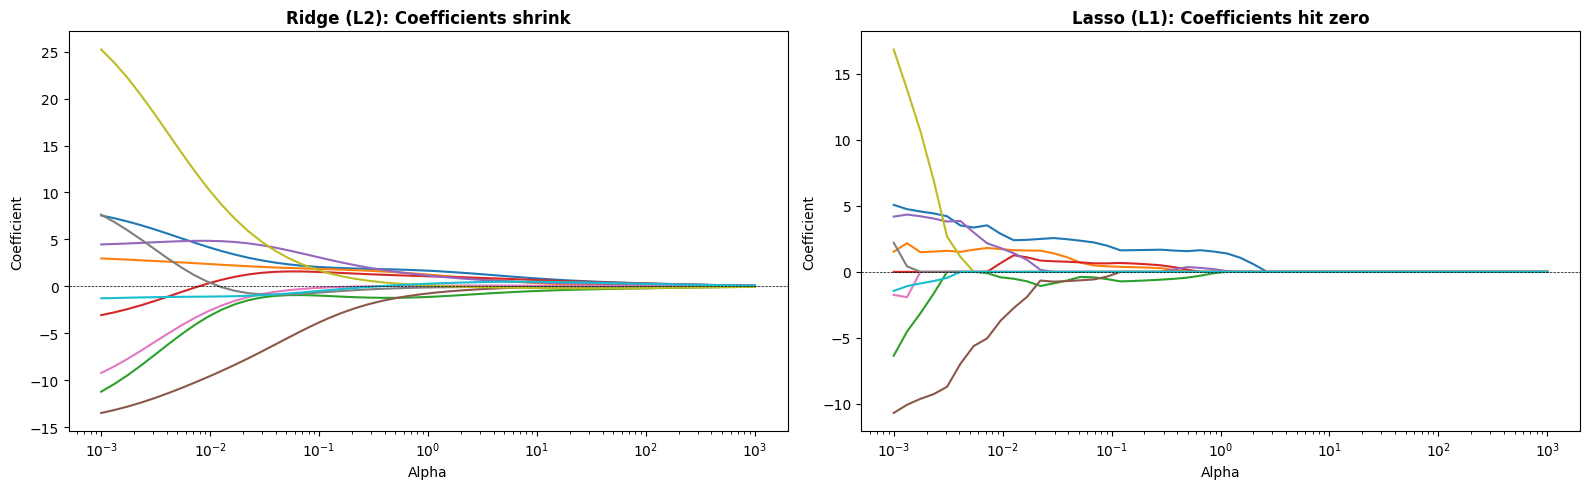

Key difference visible in the plots:
  - Ridge: coefficients smoothly approach zero but never reach it
  - Lasso: coefficients hit zero one by one as alpha increases
  - Lasso is a built-in feature selector!


In [8]:
# ─────────────────────────────────────────────────────
# LASSO COEFFICIENT PATHS — Features getting eliminated
# ─────────────────────────────────────────────────────
lasso_coef_paths = []

for alpha in alpha_range:
    lasso = Lasso(alpha=alpha, max_iter=10000)
    lasso.fit(X_train_poly, y_train)
    lasso_coef_paths.append(lasso.coef_)

lasso_coef_paths = np.array(lasso_coef_paths)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# ── Ridge paths ──
ax = axes[0]
for i in range(min(10, coef_paths.shape[1])):
    ax.plot(alpha_range, coef_paths[:, i], linewidth=1.5)
ax.set_xscale('log')
ax.set_xlabel('Alpha')
ax.set_ylabel('Coefficient')
ax.set_title('Ridge (L2): Coefficients shrink', fontweight='bold')
ax.axhline(0, color='black', linewidth=0.5, linestyle='--')

# ── Lasso paths ──
ax = axes[1]
for i in range(min(10, lasso_coef_paths.shape[1])):
    ax.plot(alpha_range, lasso_coef_paths[:, i], linewidth=1.5)
ax.set_xscale('log')
ax.set_xlabel('Alpha')
ax.set_ylabel('Coefficient')
ax.set_title('Lasso (L1): Coefficients hit zero', fontweight='bold')
ax.axhline(0, color='black', linewidth=0.5, linestyle='--')

plt.tight_layout()
plt.savefig('ridge_vs_lasso_paths.png', dpi=100, bbox_inches='tight')
plt.show()

print("Key difference visible in the plots:")
print("  - Ridge: coefficients smoothly approach zero but never reach it")
print("  - Lasso: coefficients hit zero one by one as alpha increases")
print("  - Lasso is a built-in feature selector!")

## Part 5: Comparing All Three Models

Let us compare plain polynomial, Ridge, and Lasso on our settlement prediction task.

---

In [9]:
# ─────────────────────────────────────────────────────
# HEAD-TO-HEAD COMPARISON
# ─────────────────────────────────────────────────────
models = {
    'Linear (deg=1)': Pipeline([
        ('scaler', StandardScaler()),
        ('lr', LinearRegression())
    ]),
    'Polynomial (deg=3)': Pipeline([
        ('poly', PolynomialFeatures(degree=3, include_bias=False)),
        ('scaler', StandardScaler()),
        ('lr', LinearRegression())
    ]),
    'Ridge (deg=3, a=1)': Pipeline([
        ('poly', PolynomialFeatures(degree=3, include_bias=False)),
        ('scaler', StandardScaler()),
        ('ridge', Ridge(alpha=1.0))
    ]),
    'Lasso (deg=3, a=0.1)': Pipeline([
        ('poly', PolynomialFeatures(degree=3, include_bias=False)),
        ('scaler', StandardScaler()),
        ('lasso', Lasso(alpha=0.1, max_iter=10000))
    ]),
}

comparison = []
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    comparison.append({
        'Model': name,
        'R2_train': r2_score(y_train, model.predict(X_train)),
        'R2_test': r2_score(y_test, y_pred),
        'RMSE_test': np.sqrt(mean_squared_error(y_test, y_pred)),
    })

comp_df = pd.DataFrame(comparison)
print("Model Comparison — Settlement Prediction")
print("=" * 65)
print(comp_df.to_string(index=False))

Model Comparison — Settlement Prediction
               Model  R2_train  R2_test  RMSE_test
      Linear (deg=1)  0.770859 0.775558   1.622997
  Polynomial (deg=3)  0.901226 0.618327   2.116466
  Ridge (deg=3, a=1)  0.835615 0.877001   1.201480
Lasso (deg=3, a=0.1)  0.778451 0.800517   1.530094


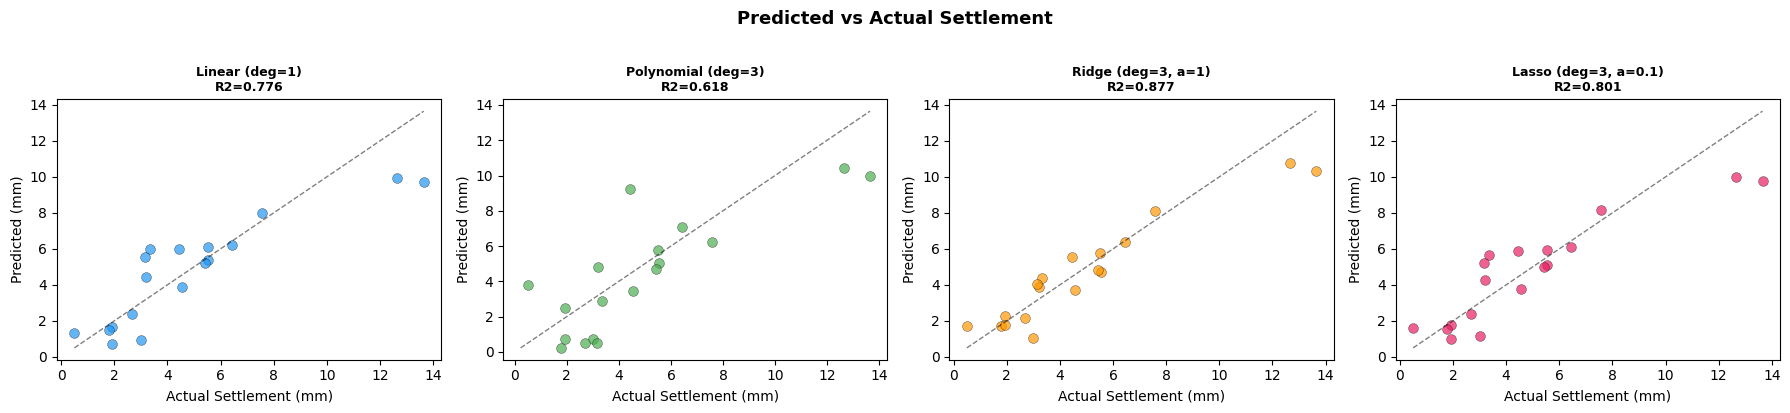

In [10]:
# ─────────────────────────────────────────────────────
# PREDICTED vs ACTUAL — Visual comparison
# ─────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
colors = ['#2196F3', '#4CAF50', '#FF9800', '#E91E63']

for ax, (name, y_pred), color in zip(axes, predictions.items(), colors):
    ax.scatter(y_test, y_pred, c=color, edgecolors='black', linewidth=0.3,
               alpha=0.7, s=50)
    # Perfect prediction line
    lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
    ax.plot(lims, lims, 'k--', linewidth=1, alpha=0.5)
    r2 = r2_score(y_test, y_pred)
    ax.set_title(f'{name}\nR2={r2:.3f}', fontweight='bold', fontsize=9)
    ax.set_xlabel('Actual Settlement (mm)')
    ax.set_ylabel('Predicted (mm)')

plt.suptitle('Predicted vs Actual Settlement', fontweight='bold', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('model_comparison.png', dpi=100, bbox_inches='tight')
plt.show()

## Part 6: Alpha Tuning with Cross-Validation

How do we choose the best alpha? Use cross-validation to find the value
that gives the best test performance.

---

In [11]:
# ─────────────────────────────────────────────────────
# ALPHA TUNING VIA CROSS-VALIDATION
# ─────────────────────────────────────────────────────
from sklearn.linear_model import RidgeCV, LassoCV

# ── Prepare polynomial features ──
poly = PolynomialFeatures(degree=3, include_bias=False)
scaler = StandardScaler()
X_train_p = scaler.fit_transform(poly.fit_transform(X_train))
X_test_p = scaler.transform(poly.transform(X_test))

# ── Ridge CV ──
ridge_cv = RidgeCV(alphas=np.logspace(-3, 3, 50), cv=5)
ridge_cv.fit(X_train_p, y_train)
print(f"Ridge CV: Best alpha = {ridge_cv.alpha_:.4f}")
print(f"  Train R2 = {ridge_cv.score(X_train_p, y_train):.4f}")
print(f"  Test  R2 = {ridge_cv.score(X_test_p, y_test):.4f}")

# ── Lasso CV ──
lasso_cv = LassoCV(alphas=np.logspace(-3, 2, 50), cv=5, max_iter=10000)
lasso_cv.fit(X_train_p, y_train)
print(f"\nLasso CV: Best alpha = {lasso_cv.alpha_:.4f}")
print(f"  Train R2 = {lasso_cv.score(X_train_p, y_train):.4f}")
print(f"  Test  R2 = {lasso_cv.score(X_test_p, y_test):.4f}")
n_nonzero = np.sum(np.abs(lasso_cv.coef_) > 1e-6)
print(f"  Features used: {n_nonzero} / {X_train_p.shape[1]}")

Ridge CV: Best alpha = 0.0687
  Train R2 = 0.8736
  Test  R2 = 0.8492



Lasso CV: Best alpha = 0.2223
  Train R2 = 0.7623
  Test  R2 = 0.7654
  Features used: 4 / 19


In [12]:
# ─────────────────────────────────────────────────────
# WHICH FEATURES DID LASSO KEEP?
# ─────────────────────────────────────────────────────
feature_names = poly.get_feature_names_out()
lasso_coefs = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': lasso_cv.coef_
})

# Sort by absolute value
lasso_coefs['Abs_Coef'] = lasso_coefs['Coefficient'].abs()
lasso_coefs = lasso_coefs.sort_values('Abs_Coef', ascending=False)

print("Lasso Feature Selection — Most Important Features")
print("=" * 55)
print(f"Total polynomial features: {len(feature_names)}")
print(f"Features kept by Lasso: {n_nonzero}")
print(f"Features eliminated: {len(feature_names) - n_nonzero}")
print()

kept = lasso_coefs[lasso_coefs['Abs_Coef'] > 1e-6]
print("Kept features (sorted by importance):")
for _, row in kept.iterrows():
    print(f"  {row['Feature']:30s}  coef = {row['Coefficient']:+.4f}")

print("\nLasso automatically identified the most important polynomial terms!")
print("This is much better than manually selecting features.")

Lasso Feature Selection — Most Important Features
Total polynomial features: 19
Features kept by Lasso: 4
Features eliminated: 15

Kept features (sorted by importance):
  x0                              coef = +1.6614
  x2                              coef = -0.6387
  x0^2                            coef = +0.5631
  x1                              coef = +0.3169

Lasso automatically identified the most important polynomial terms!
This is much better than manually selecting features.


---

## Practice Exercises

### Exercise 1: Degree and Alpha Interaction
Try degree=5 polynomial with Ridge. Find the alpha that prevents overfitting.
Compare the test R2 with degree=3.

### Exercise 2: ElasticNet
ElasticNet combines Ridge and Lasso penalties. Import `ElasticNet` from sklearn
and try `l1_ratio=0.5` (equal mix). Compare with pure Ridge and pure Lasso.

### Exercise 3: Feature Importance Plot
Create a horizontal bar chart of the top 10 most important features from the
Lasso model. Which original features (pressure, width, depth) appear most often?

---

In [13]:
# ─────────────────────────────────────────────────────
# EXERCISE 1: Degree 5 with Ridge
# ─────────────────────────────────────────────────────
# poly5 = PolynomialFeatures(degree=5, include_bias=False)
# scaler5 = StandardScaler()
# X_train_5 = scaler5.fit_transform(poly5.fit_transform(X_train))
# X_test_5 = scaler5.transform(poly5.transform(X_test))
#
# ridge_cv5 = RidgeCV(alphas=np.logspace(-2, 4, 50), cv=5)
# ridge_cv5.fit(X_train_5, y_train)
# print(f"Degree 5 Ridge: alpha={ridge_cv5.alpha_:.2f}, R2={ridge_cv5.score(X_test_5, y_test):.4f}")

In [14]:
# ─────────────────────────────────────────────────────
# EXERCISE 2: ElasticNet
# ─────────────────────────────────────────────────────
# from sklearn.linear_model import ElasticNet
# en = ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=10000)
# en.fit(X_train_p, y_train)
# print(f"ElasticNet R2: {en.score(X_test_p, y_test):.4f}")
# print(f"Features used: {np.sum(np.abs(en.coef_) > 1e-6)}")

---

## Key Takeaways

1. **Polynomial regression captures nonlinear relationships** like pressure-settlement curves. But high degrees overfit badly — the model memorizes noise.

2. **Ridge (L2) shrinks all coefficients** toward zero, reducing overfitting while keeping all features. Use when you believe all features contribute.

3. **Lasso (L1) drives some coefficients to exactly zero**, performing automatic feature selection. Use when you suspect many features are irrelevant.

4. **Alpha controls the bias-variance tradeoff.** Too small = overfitting, too large = underfitting. Cross-validation finds the sweet spot.

5. **In geotechnical engineering, regularization is essential** because we often have many correlated features (e.g., soil properties) and limited samples. Regularization prevents models from fitting noise in our measurements.

---

## How This Connects to ML

| What We Did Today | What It Becomes in ML |
|---|---|
| PolynomialFeatures | Nonlinear feature engineering for any algorithm |
| Overfitting with high degree | Why model complexity must be controlled |
| Ridge (L2) | Foundation for regularized neural networks |
| Lasso (L1) | Automatic feature selection in high-dimensional problems |
| Alpha tuning with CV | Hyperparameter optimization (a core ML skill) |
| Coefficient paths | Understanding how regularization affects model behavior |

---

*Day 038 of 100 — Keep going!*